# Gumbel Analysis Training Notebook

In [1]:
import shutil
import os
import random
import numpy as np
import torch
import torch.optim as optim
from emulator import Emulator
from training import (
    train_model_disk,
    InverseSqrtScheduler,
    DiskBackedBufferManagerCholesky,
)
from utils import get_device

In [2]:
def set_seed(seed=42):
    """Set all random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = get_device()

In [3]:
def train(ks, emulator_config, lambda_grad=1e-4, seed=42, data_dir="./analysis-data-checkpoints"):
    set_seed(seed)
    model = Emulator(**emulator_config).to(device)
    
    # ============================================================================
    # Print model summary
    # ============================================================================
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\nModel: {model.name}")
    print(f"Training on K values: {ks}")
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Config: {emulator_config}")
    
    # ============================================================================
    # Optimizer configuration
    # ============================================================================
    optimizer = optim.AdamW(
        model.parameters(), 
        lr=0.003, 
        betas=(0.9, 0.999), 
        eps=1e-8, 
        weight_decay=3e-6,
    )
    scheduler = InverseSqrtScheduler(optimizer, warmup_steps=5000, min_lr_ratio=0.)
    
    # ============================================================================
    # Training configuration
    # ============================================================================
    num_epochs = 200_000
    num_samples = 1_000_000
    batch_size = 10_000
    eval_batch_size = 10_000
    eval_every = 100
    refresh_every = 100
    
    # ============================================================================
    # Train with context manager for proper cleanup
    # ============================================================================
    with DiskBackedBufferManagerCholesky(
        data_dir=data_dir,
        k_values=ks,
        in_memory_size=50_000,
        use_sobolev=(lambda_grad is not None),
        gumbel=True,
        device=device,
        num_workers=8,
    ) as manager:
        model, df = train_model_disk(
            model=model,
            manager=manager,
            optimizer=optimizer,
            num_epochs=num_epochs,
            num_samples=num_samples,
            batch_size=batch_size,
            eval_every=eval_every,
            eval_batch_size=eval_batch_size,
            scheduler=scheduler,
            plot=True,
            lambda_grad=lambda_grad,
            refresh_every=refresh_every,
        )

    return model, df

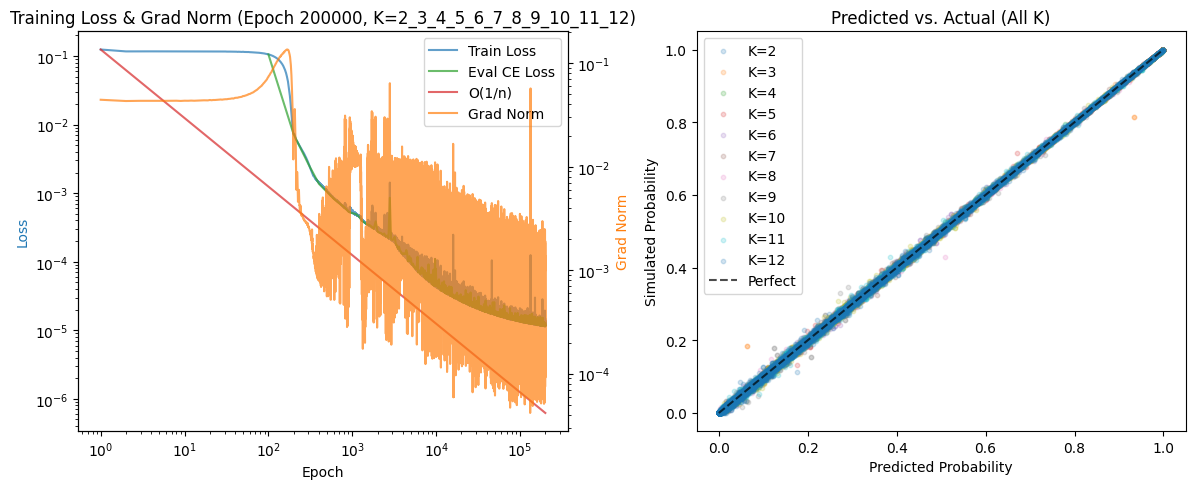

100%|██████████| 200000/200000 [21:49:54<00:00,  2.49s/it]

100%|██████████| 200000/200000 [21:49:54<00:00,  2.54it/s]


CPU Forward Pass Timing (batch_size=10000, K=2):
  Current:  31.42 ms total, 3.14 µs/sample
  Average:  20.30 ms total, 2.03 µs/sample
  Optimizer: AdamW
  Training on K values: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
  In-memory buffer size: 50,000
  Directional derivative training: lambda_grad=0.0001, num_directions=1, epsilon=1e-05
  Last train CE loss: 0.000012, grad loss: 0.003907


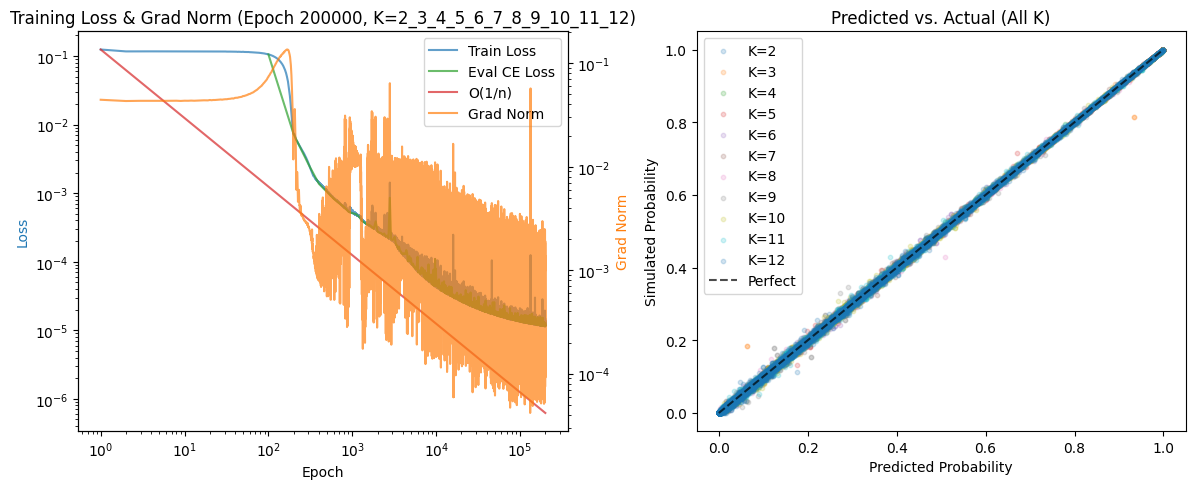

In [4]:
ks = list(range(2, 13))  # K=2, 3,..., 12
lambda_grad = 1e-4

# Copy to /tmp, which is an optimized disk in our compute environment
original_data_dir = "gumbel-analysis-data-checkpoints"
data_dir = os.path.join("/tmp/dc-emulator", original_data_dir)
if os.path.exists(data_dir):
    print("Deleting old data")
    shutil.rmtree(data_dir)
print("Copying data to fast drive")
shutil.copytree(original_data_dir, data_dir)

# Emulator parameters
emulator_config = {
    'name': 'gumbel',
    # Diagonal DeepSet
    'diag_phi_hidden_dim': 64,
    'diag_phi_output_dim': 64,
    'diag_phi_num_layers': 1,
    'diag_rho_hidden_dim': 32,
    'diag_rho_output_dim': 32,
    'diag_rho_num_layers': 1,
    # Off-diagonal DeepSet
    'offdiag_phi_hidden_dim': 64,
    'offdiag_phi_output_dim': 64,
    'offdiag_phi_num_layers': 1,
    'offdiag_rho_hidden_dim': 32,
    'offdiag_rho_output_dim': 32,
    'offdiag_rho_num_layers': 1,
    # Combining MLP
    'combine_hidden_dim': 64,
    'combine_output_dim': 32,
    'combine_num_layers': 2,
    # Equivariant layers
    'equiv_hidden_dim': 16,
    'num_equiv_layers': 1,
    # Shared
    'dropout_rate': 0.1,
    'include_k': len(ks) > 1,
    'include_c_star': True
}

model, training_df = train(ks, emulator_config, lambda_grad=lambda_grad, data_dir=data_dir)

In [5]:
if os.path.exists(data_dir):
    shutil.rmtree(data_dir)